In [9]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
import pandas as pd

# Statistics Lab

## Basic concepts

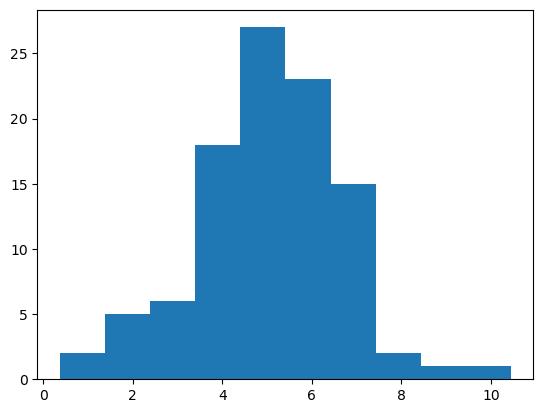

In [2]:
results = norm.rvs(loc = 5, scale = 1.5, size = 100)
plt.hist(results)
plt.show()

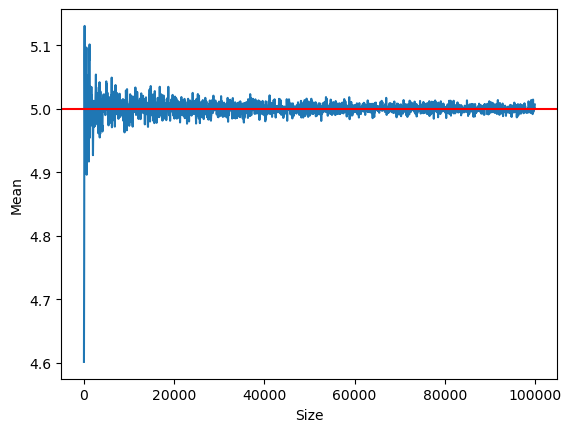

In [8]:
sizes = range(10, 100000, 50)
means = []
for size in sizes:
    results = norm.rvs(loc = 5, scale = 1.5, size = size)
    means.append(results.mean())

plt.plot(sizes, means)
plt.axhline(5, c = "red")
plt.xlabel("Size")
plt.ylabel("Mean")
plt.show()

## Propertiies of distributions

In [12]:
snowfall_data = pd.read_table("snowfall.csv", header = None)

In [13]:
snowfall_data

,0
0,126.4
1,82.4
2,78.1
3,51.1
4,90.9
...,...
58,66.1
59,78.4
60,120.5
61,97.0


In [14]:
snowfall_data.columns = ["snowfall"]

In [15]:
snowfall_data

,snowfall
0,126.4
1,82.4
2,78.1
3,51.1
4,90.9
...,...
58,66.1
59,78.4
60,120.5
61,97.0


In [16]:
snowfall_data["snowfall"]

0     126.4
1      82.4
2      78.1
3      51.1
4      90.9
      ...  
58     66.1
59     78.4
60    120.5
61     97.0
62    110.0
Name: snowfall, Length: 63, dtype: float64

In [17]:
snowfall_data["snowfall"].mean()

80.2968253968254

In [18]:
snowfall_data["snowfall"].std()

23.71976831915066

(array([1., 0., 0., 0., 0., 0., 0., 3., 0., 0., 1., 1., 2., 1., 2., 2., 1.,
        1., 0., 2., 1., 1., 3., 2., 1., 1., 6., 1., 5., 2., 1., 3., 2., 0.,
        0., 1., 1., 1., 2., 2., 0., 1., 2., 1., 2., 0., 0., 2., 0., 2.]),
 array([ 25.   ,  27.028,  29.056,  31.084,  33.112,  35.14 ,  37.168,
         39.196,  41.224,  43.252,  45.28 ,  47.308,  49.336,  51.364,
         53.392,  55.42 ,  57.448,  59.476,  61.504,  63.532,  65.56 ,
         67.588,  69.616,  71.644,  73.672,  75.7  ,  77.728,  79.756,
         81.784,  83.812,  85.84 ,  87.868,  89.896,  91.924,  93.952,
         95.98 ,  98.008, 100.036, 102.064, 104.092, 106.12 , 108.148,
        110.176, 112.204, 114.232, 116.26 , 118.288, 120.316, 122.344,
        124.372, 126.4  ]),
 <BarContainer object of 50 artists>)

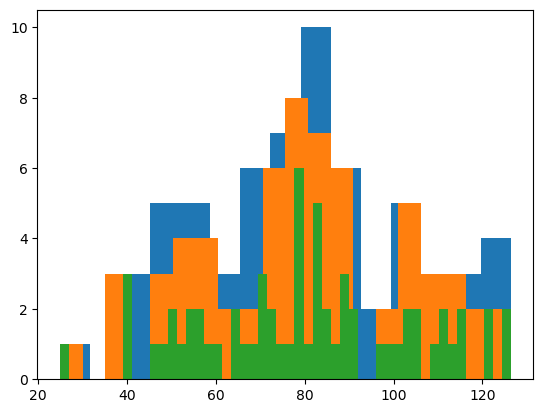

In [22]:
plt.hist(snowfall_data["snowfall"], bins = 15)
plt.hist(snowfall_data["snowfall"], bins = 20)
plt.hist(snowfall_data["snowfall"], bins = 50)

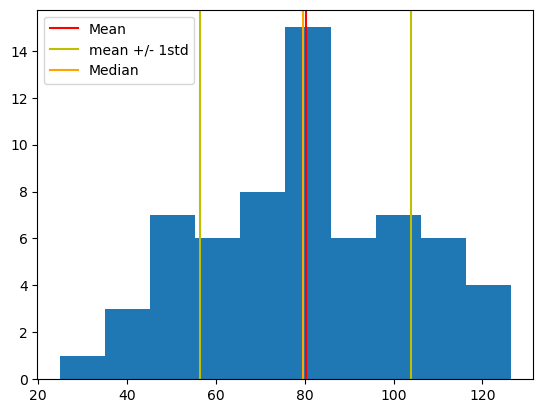

In [33]:
plt.hist(snowfall_data["snowfall"], bins = 10)
plt.axvline(snowfall_data["snowfall"].mean(), c = "red", label = "Mean")
plt.axvline(snowfall_data["snowfall"].mean() - snowfall_data["snowfall"].std(), c = "y", label = "mean +/- 1std")
plt.axvline(snowfall_data["snowfall"].mean() + snowfall_data["snowfall"].std(), c = "y")
plt.axvline(snowfall_data["snowfall"].median(), c = "orange", label = "Median")
plt.legend()
plt.show()

In [26]:
snowfall = snowfall_data["snowfall"]

lower_bound = snowfall_data["snowfall"].mean() - snowfall_data["snowfall"].std()
upper_bound = snowfall_data["snowfall"].mean() + snowfall_data["snowfall"].std()

In [27]:
lower_bound, upper_bound

(56.57705707767474, 104.01659371597606)

In [29]:
snowfall_within_1std = snowfall [
    (snowfall >= lower_bound) &
    (snowfall <= upper_bound)
]

len(snowfall_within_1std) / len(snowfall)

0.6031746031746031

In [34]:
snowfall.median()

79.7

In [35]:
snowfall_data.describe().T

,count,mean,std,min,25%,50%,75%,max
snowfall,63.0,80.296825,23.719768,25.0,64.5,79.7,97.65,126.4


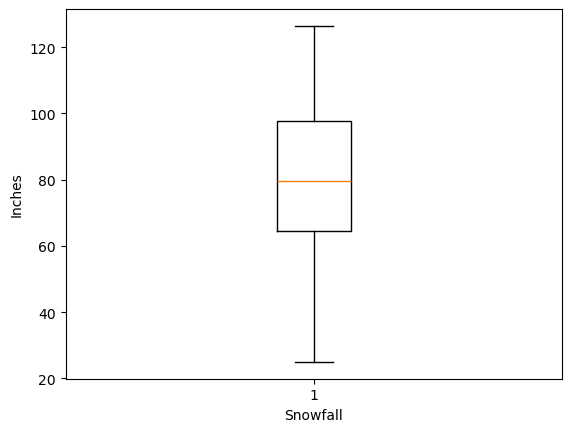

In [37]:
plt.boxplot(snowfall)
plt.xlabel("Snowfall")
plt.ylabel("Inches")
plt.show()

{'whiskers': [<matplotlib.lines.Line2D at 0x202f24b26f0>,
 'caps': [<matplotlib.lines.Line2D at 0x202f24b2c00>,
 'boxes': [<matplotlib.lines.Line2D at 0x202f1757dd0>],
 'medians': [<matplotlib.lines.Line2D at 0x202f24b3140>],
 'fliers': [<matplotlib.lines.Line2D at 0x202f24b33b0>],
 'means': []}

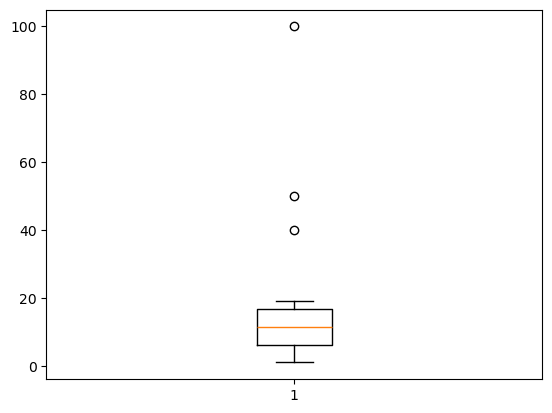

In [40]:
data = list(range(1, 20))
data += [40, 50, 100]

plt.boxplot(data)

(array([10.,  9.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  1.]),
 array([  1. ,  10.9,  20.8,  30.7,  40.6,  50.5,  60.4,  70.3,  80.2,
         90.1, 100. ]),
 <BarContainer object of 10 artists>)

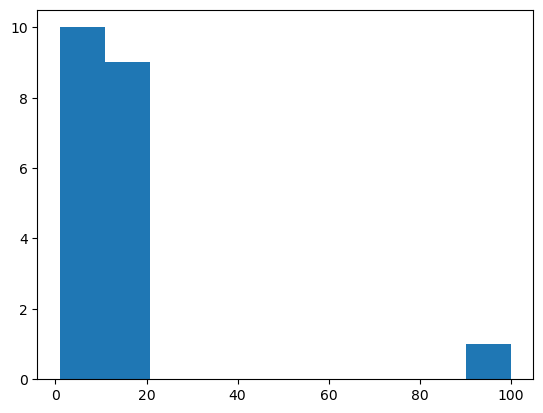

In [39]:
data = pd.Series(data)

plt.hist(data)

## Many variables

In [42]:
x = np.linspace(-3, 3, 10000)
y = x ** 2

np.corrcoef(x, y)

array([[1.00000000e+00, 2.55546137e-16],
       [2.55546137e-16, 1.00000000e+00]])

In [45]:
birth_rate_data = pd.read_table("birth_rates.csv")

birth_rate_data

,Birthrate,Year
0,183.1,1917
1,183.9,1918
2,163.1,1919
3,179.5,1920
4,181.4,1921
5,173.4,1922
6,167.6,1923
7,177.4,1924
8,171.7,1925
9,170.1,1926


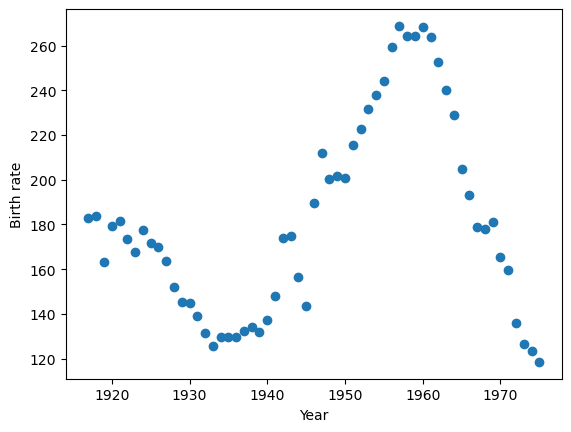

In [46]:
plt.scatter(birth_rate_data["Year"], birth_rate_data["Birthrate"])
plt.xlabel("Year")
plt.ylabel("Birth rate")
plt.show()

In [76]:
brain_body_data = pd.read_table("brain_weight.csv")

In [77]:
brain_body_data

,brain,body
0,1.350,8.1
1,465.000,423.0
2,36.330,119.5
3,27.660,115.0
4,1.040,5.5
5,11700.000,50.0
6,2547.000,4603.0
7,187.100,419.0
8,521.000,655.0
9,10.000,115.0


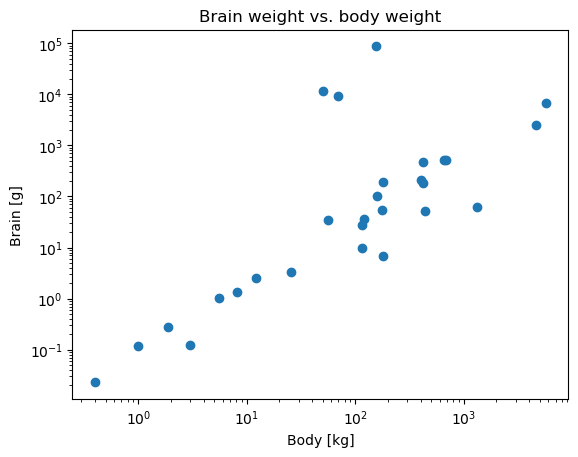

In [78]:
plt.scatter(brain_body_data["body"], brain_body_data["brain"])
plt.loglog()

plt.xlabel("Body [kg]")
plt.ylabel("Brain [g]")
plt.title("Brain weight vs. body weight")
plt.show()

In [80]:
brain_body_data.describe().T

,count,mean,std,min,25%,50%,75%,max
brain,28.0,4278.438750,16480.490379,0.023,3.100,53.83,479.0,87000.0
body,28.0,574.521429,1334.929191,0.400,22.225,137.00,420.0,5712.0


In [81]:
brain_body_data.corr()

,brain,body
brain,1.000000,-0.005341
body,-0.005341,1.000000


In [82]:
np.corrcoef(np.log10(brain_body_data["brain"]), np.log10(brain_body_data["body"]))

array([[1.       , 0.7794935],
       [0.7794935, 1.       ]])